# Application with the flowers dataset

### 1. All useful import

In [ ]:
import os
import sys
import random
import math
import numpy as np
import skimage.io
import matplotlib.pyplot as plt

# Root directory of the project
ROOT_DIR = os.getcwd()

# Import COCO config
import coco

# Import Mask RCNN
from mrcnn import utils
import mrcnn.model as modellib
from mrcnn import visualize

# Directory to save logs and trained model
MODEL_DIR = os.path.join(ROOT_DIR, "logs")

Using TensorFlow backend.


### 2. Create the dryas config to fit with the model
It is unnecessary if you use the model imported from the GitHub repository [TECOLOGYxyz](https://github.com/TECOLOGYxyz/Mask_RCNN/tree/master).


In [ ]:
from mrcnn.config import Config

class DryasConfig(Config):
    """Configuration for training on the dryas dataset.
    Derives from the base Config class and overrides some values.
    """
    # Give the configuration a recognizable name
    NAME = "2020_07_01_NorwayAnnotations_TheUltimateModel"

    # We use a GPU with 12GB memory, which can fit two images.
    # Adjust down if you use a smaller GPU.
    IMAGES_PER_GPU = 1

    # Number of classes (including background)
    NUM_CLASSES = 1 + 1  # Background + (flower + syrphidae)

    # Number of training steps per epoch
    STEPS_PER_EPOCH = 100

    # Skip detections with < 90% confidence
    DETECTION_MIN_CONFIDENCE = 0.9
config = DryasConfig()
#config.display()

### 3. Recover the model and some test images without extracting all the dataset

In [ ]:
import zipfile

zip_path = "Data_AutomaticDetectionFlower.zip"
files_to_extract = ["data/images/1-hr/test/NARS-04_000006.JPG","data/images/1-hr/test/NYALE-04_000418.JPG",  "data/images/1-hr/test/NARS-04_000332.JPG",  "data/flowerDetectionModels/Dryas_1.h5"]

with zipfile.ZipFile(zip_path, 'r') as z:
    for name in files_to_extract:
        z.extract(name, path="dossier_sortie")


In [3]:
DRYAS_MODEL_PATH = os.path.join(ROOT_DIR, "dossier_sortie/data/flowerDetectionModels/Dryas_2.h5")

IMAGE_DIR = os.path.join(ROOT_DIR, "dossier_sortie/data/images/1-hr/test")

### 4. Creating the model and detecting the flowers

In [4]:
# Create model object in inference mode.
model = modellib.MaskRCNN(mode="inference", model_dir=MODEL_DIR, config=config)

# Load weights trained on the dataset provided by the scientific article
model.load_weights(DRYAS_MODEL_PATH, by_name=True)

Instructions for updating:
If using Keras pass *_constraint arguments to layers.


Instructions for updating:
Use tf.where in 2.0, which has the same broadcast rule as np.where
Instructions for updating:
box_ind is deprecated, use box_indices instead


Instructions for updating:
Use `tf.cast` instead.


Processing 1 images
image                    shape: (427, 760, 3)         min:    0.00000  max:  255.00000  uint8
molded_images            shape: (1, 1024, 1024, 3)    min: -123.70000  max:  151.10000  float64
image_metas              shape: (1, 14)               min:    0.00000  max: 1024.00000  float64
anchors                  shape: (1, 261888, 4)        min:   -0.35390  max:    1.29134  float32
rois shape: (0, 4)
scores: []
class_ids: []

*** No instances to display *** 



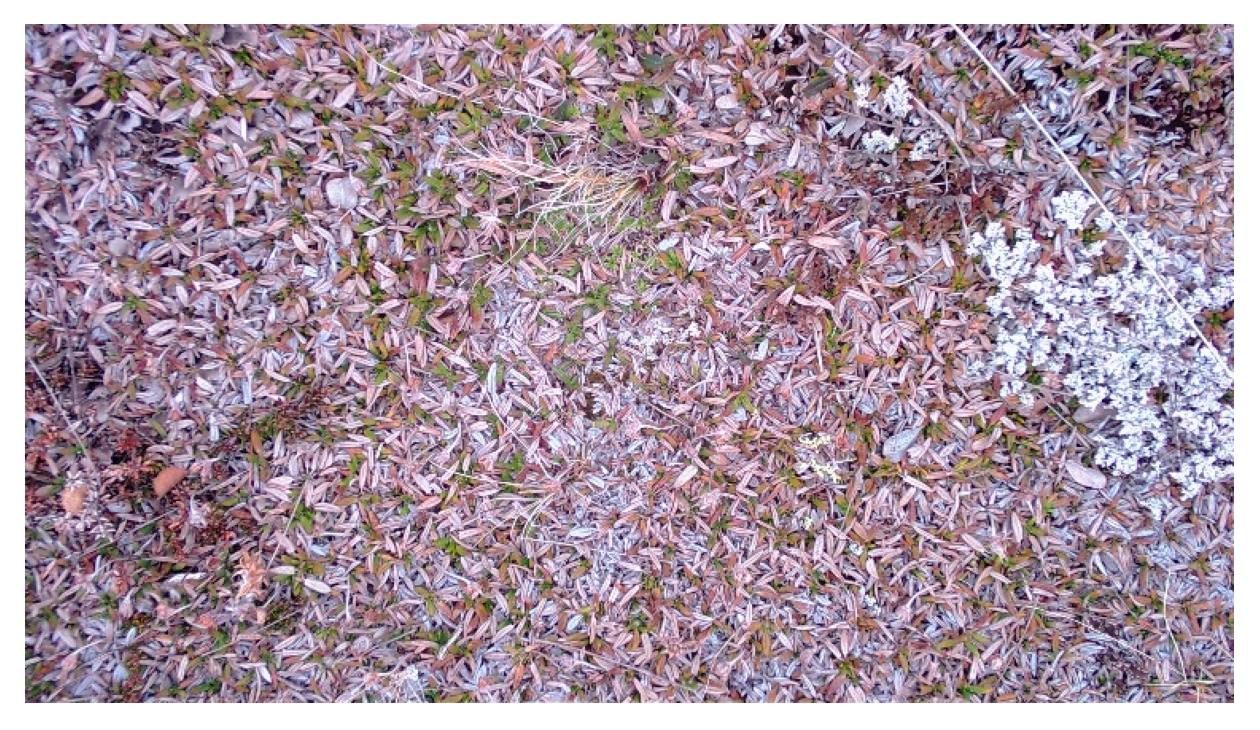

Processing 1 images
image                    shape: (427, 760, 3)         min:    0.00000  max:  255.00000  uint8
molded_images            shape: (1, 1024, 1024, 3)    min: -123.70000  max:  151.10000  float64
image_metas              shape: (1, 14)               min:    0.00000  max: 1024.00000  float64
anchors                  shape: (1, 261888, 4)        min:   -0.35390  max:    1.29134  float32
rois shape: (5, 4)
scores: [0.9999727  0.9999205  0.99991786 0.99990726 0.99741614]
class_ids: [1 1 1 1 1]


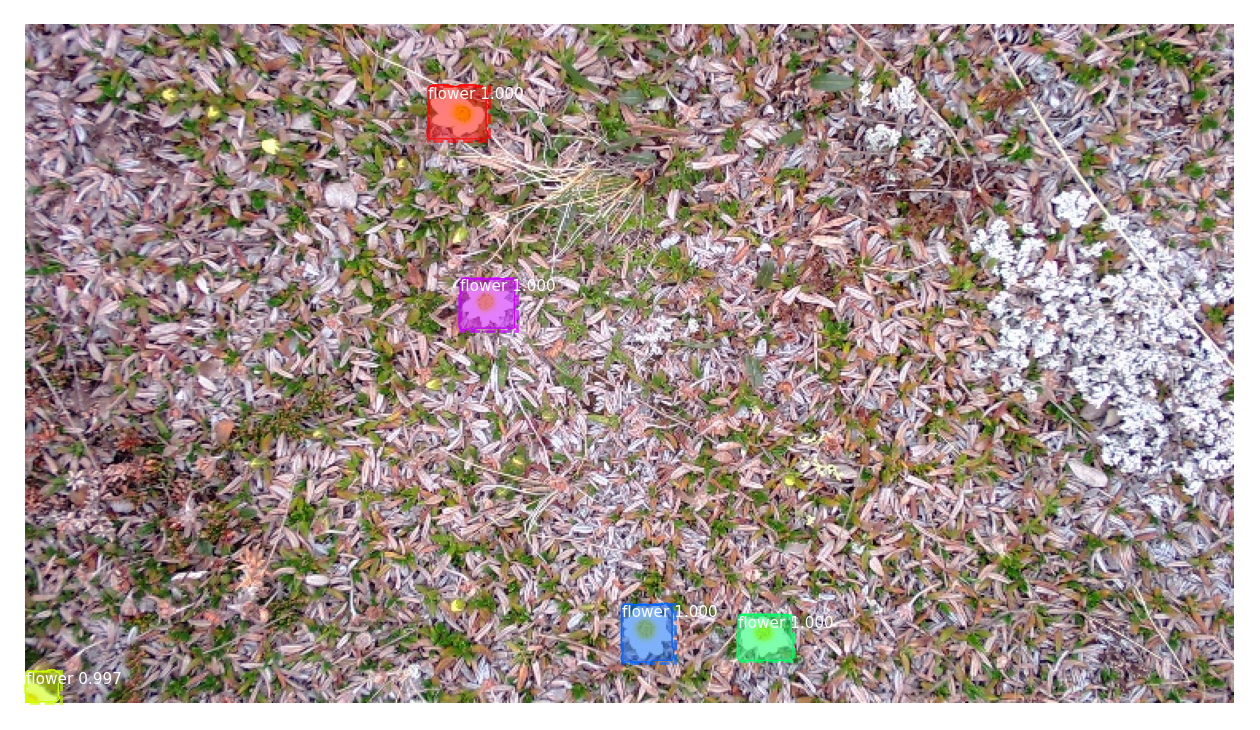

In [ ]:
%matplotlib inline

class_names = ['BG',"flower"]

# Load a random image from the images folder
file_names = next(os.walk(IMAGE_DIR))[2]

for i in range(min(len(file_names), 5)):
    image = skimage.io.imread(os.path.join(IMAGE_DIR, file_names[i]))

    # Run detection
    results = model.detect([image], verbose=1)

    # Visualize results
    r = results[0]
    visualize.display_instances(image, r['rois'], r['masks'], r['class_ids'], 
                            class_names, r['scores'])
